# 10 — Model Explainability

Bu notebook yeni model aramaz. `09_advanced_model_selection.ipynb` içinde seçilmiş LightGBM modelini, aynı ABCD feature setini ve aynı iki uzmanlı expanding-window validation düzenini yeniden kurar; model davranışını feature importance, SHAP, residual, temporal/spatial hata ve stability analizleriyle açıklar.

Temel sınırlar:

- Test target'ı kullanılmaz.
- Validation tarihleri bütün halde tutulur.
- Testteki TWS maskesi her 18-tarihli validation bloğunda taklit edilir.
- `TWS_t` bilinen ve maskeli satırlar ayrı uzmanlarla değerlendirilir.
- SHAP opsiyoneldir; bulunmadığında diğer tüm hücreler çalışır.
- Belirsizlik için modelin gerçek olasılıksal güveni değil, fold modelleri arasındaki tahmin yayılımı kullanılır.

In [1]:
from pathlib import Path
from time import perf_counter
import importlib.util, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (root_mean_squared_error, mean_absolute_error,
                             median_absolute_error, r2_score)
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
SEED=42
np.random.seed(SEED)
sns.set_theme(style="whitegrid",context="notebook")
pd.set_option("display.max_columns",100)

def find_repo_root(start=None):
    p=Path(start or Path.cwd()).resolve()
    for candidate in [p,*p.parents]:
        if (candidate/"data"/"raw"/"Train.csv").exists():
            return candidate
    raise FileNotFoundError("Repository root bulunamadı.")

ROOT=find_repo_root()
DATA=ROOT/"data"/"raw"
SUBMISSION_PATH=ROOT/"submissions"/"submission_advanced_model.csv"
print("ROOT:",ROOT)

ROOT: C:\global-water-storage-forecasting


## 1. Aynı veri, preprocessing ve feature engineering

In [2]:
train=pd.read_csv(DATA/"Train.csv",parse_dates=["time"])
test=pd.read_csv(DATA/"Test.csv",parse_dates=["time"])
sample_submission=pd.read_csv(DATA/"SampleSubmission.csv")
submission=pd.read_csv(SUBMISSION_PATH)

assert train.sample_id.is_unique and test.ID.is_unique
assert test.ID.equals(sample_submission.ID)
assert submission.ID.equals(sample_submission.ID)
assert np.isfinite(submission.Target).all()
print("Shapes:",train.shape,test.shape,submission.shape)
print("Test TWS missing share:",test.TWS_t.isna().mean())

Shapes: (2154021, 13) (280961, 13) (280961, 2)
Test TWS missing share: 0.6652631504016572


In [3]:
SPEI_COLS=["SPEI_01_t","SPEI_03_t","SPEI_06_t","SPEI_12_t"]

def add_safe_date_features(df):
    out=df.copy(); dt=pd.to_datetime(out["time"])
    out["month"]=dt.dt.month.astype("int8")
    out["quarter"]=dt.dt.quarter.astype("int8")
    out["year"]=dt.dt.year.astype("int16")
    out["elapsed_month"]=((dt.dt.year-train.time.dt.year.min())*12+dt.dt.month-1).astype("int16")
    out["month_sin_calc"]=np.sin(2*np.pi*out.month/12)
    out["month_cos_calc"]=np.cos(2*np.pi*out.month/12)
    out["season_sin"]=np.sin(2*np.pi*out.quarter/4)
    out["season_cos"]=np.cos(2*np.pi*out.quarter/4)
    return out

def add_spei_features(df):
    out=df.copy(); s=out[SPEI_COLS]
    out["spei_mean"]=s.mean(axis=1); out["spei_min"]=s.min(axis=1)
    out["spei_max"]=s.max(axis=1); out["spei_std"]=s.std(axis=1)
    out["spei_01_minus_12"]=out.SPEI_01_t-out.SPEI_12_t
    out["spei_03_minus_12"]=out.SPEI_03_t-out.SPEI_12_t
    out["spei_short_long_ratio"]=out.SPEI_01_t/(out.SPEI_12_t.abs()+.1)
    return out

def add_spatial_features(df):
    out=df.copy()
    out["lat_band_5"]=np.floor((out.lat+90)/5)
    out["lon_band_5"]=np.floor((out.lon+180)/5)
    out["spatial_bin_10"]=out.lat_band_5*100+out.lon_band_5
    out["lat_lon_interaction"]=out.lat*out.lon/1000
    out["lat_sin"]=np.sin(np.radians(out.lat)); out["lat_cos"]=np.cos(np.radians(out.lat))
    out["lon_sin"]=np.sin(np.radians(out.lon)); out["lon_cos"]=np.cos(np.radians(out.lon))
    return out

def build_features(df):
    return add_spatial_features(add_spei_features(add_safe_date_features(df)))

train_f=build_features(train); test_f=build_features(test)
A=["lat","lon","TWS_t",*SPEI_COLS,"SOIL_MOISTURE_t","month","month_sin","month_cos","year"]
B=["quarter","elapsed_month","month_sin_calc","month_cos_calc","season_sin","season_cos"]
C=["spei_mean","spei_min","spei_max","spei_std","spei_01_minus_12","spei_03_minus_12","spei_short_long_ratio"]
D=["lat_band_5","lon_band_5","spatial_bin_10","lat_lon_interaction","lat_sin","lat_cos","lon_sin","lon_cos"]
FEATURES=list(dict.fromkeys(A+B+C+D))
NO_TWS_FEATURES=[c for c in FEATURES if c!="TWS_t"]
print("Known-TWS features:",len(FEATURES),"Masked-TWS features:",len(NO_TWS_FEATURES))

Known-TWS features: 33 Masked-TWS features: 32


## 2. Aynı validation ve final model

In [4]:
PARAMS=dict(n_estimators=160,learning_rate=.08,num_leaves=63,
            min_child_samples=100,reg_lambda=1.0,subsample=.85,
            colsample_bytree=.9,random_state=SEED,n_jobs=4,verbosity=-1)

test_by_date=test.groupby("time").agg(rows=("ID","size"),known=("TWS_t","count"))
KNOWN_DATE_POSITIONS=set(np.flatnonzero(test_by_date.known.to_numpy()>test_by_date.rows.to_numpy()*.5))

def create_validation_splits(df,n_splits=3,block_dates=18):
    dates=np.array(sorted(df.time.unique()))
    start=len(dates)-n_splits*block_dates
    out=[]
    for i in range(n_splits):
        va_dates=dates[start+i*block_dates:start+(i+1)*block_dates]
        tr_dates=dates[:start+i*block_dates]
        out.append((np.flatnonzero(df.time.isin(tr_dates)),np.flatnonzero(df.time.isin(va_dates))))
    return out

MODEL_SPLITS=create_validation_splits(train_f)[-2:]
for i,(a,b) in enumerate(MODEL_SPLITS,1):
    print(i,train_f.iloc[a].time.min(),"→",train_f.iloc[a].time.max(),
          "| valid",train_f.iloc[b].time.min(),"→",train_f.iloc[b].time.max())

1 2002-05-01 00:00:00 → 2011-05-01 00:00:00 | valid 2011-08-01 00:00:00 → 2013-07-01 00:00:00


2 2002-05-01 00:00:00 → 2013-07-01 00:00:00 | valid 2013-11-01 00:00:00 → 2015-08-01 00:00:00


In [5]:
def regression_metrics(y,p):
    return {"RMSE":root_mean_squared_error(y,p),"MAE":mean_absolute_error(y,p),
            "MedianAE":median_absolute_error(y,p),"R2":r2_score(y,p)}

def fit_routed_folds(df,splits):
    fold_models=[]; parts=[]; rows=[]; importance=[]
    for fold,(tr_idx,va_idx) in enumerate(splits,1):
        tr,va=df.iloc[tr_idx],df.iloc[va_idx]
        dates=np.array(sorted(va.time.unique()))
        known=va.time.isin({d for j,d in enumerate(dates) if j in KNOWN_DATE_POSITIONS}).to_numpy()
        mk=LGBMRegressor(**PARAMS).fit(tr[FEATURES],tr.target)
        mm=LGBMRegressor(**PARAMS).fit(tr[NO_TWS_FEATURES],tr.target)
        pred=np.empty(len(va))
        pred[known]=mk.predict(va.loc[known,FEATURES])
        pred[~known]=mm.predict(va.loc[~known,NO_TWS_FEATURES])
        part=va.copy()
        part["prediction"]=pred; part["residual"]=part.target-pred
        part["absolute_error"]=part.residual.abs(); part["fold"]=fold
        part["simulated_tws_known"]=known
        parts.append(part)
        met=regression_metrics(part.target,pred)
        rows.append({"fold":fold,**met,"known_RMSE":root_mean_squared_error(part.target[known],pred[known]),
                     "masked_RMSE":root_mean_squared_error(part.target[~known],pred[~known])})
        for specialist,model,features in [("known",mk,FEATURES),("masked",mm,NO_TWS_FEATURES)]:
            importance.append(pd.DataFrame({"fold":fold,"specialist":specialist,"feature":features,
                "gain":model.booster_.feature_importance(importance_type="gain"),
                "split":model.booster_.feature_importance(importance_type="split")}))
        fold_models.append((mk,mm))
    return pd.DataFrame(rows),pd.concat(parts,ignore_index=True),pd.concat(importance,ignore_index=True),fold_models

fold_metrics,oof,fold_importance,fold_models=fit_routed_folds(train_f,MODEL_SPLITS)
display(fold_metrics)
display(fold_metrics.mean(numeric_only=True).to_frame("mean"))

,fold,RMSE,MAE,MedianAE,R2,known_RMSE,masked_RMSE
0,1,0.646900,0.495291,0.390439,0.427100,0.509031,0.705685
1,2,0.775083,0.585770,0.452407,0.145108,0.693215,0.812902


,mean
fold,1.500000
RMSE,0.710991
MAE,0.540530
MedianAE,0.421423
R2,0.286104
known_RMSE,0.601123
masked_RMSE,0.759294


## 3. Built-in gain/split ve permutation importance

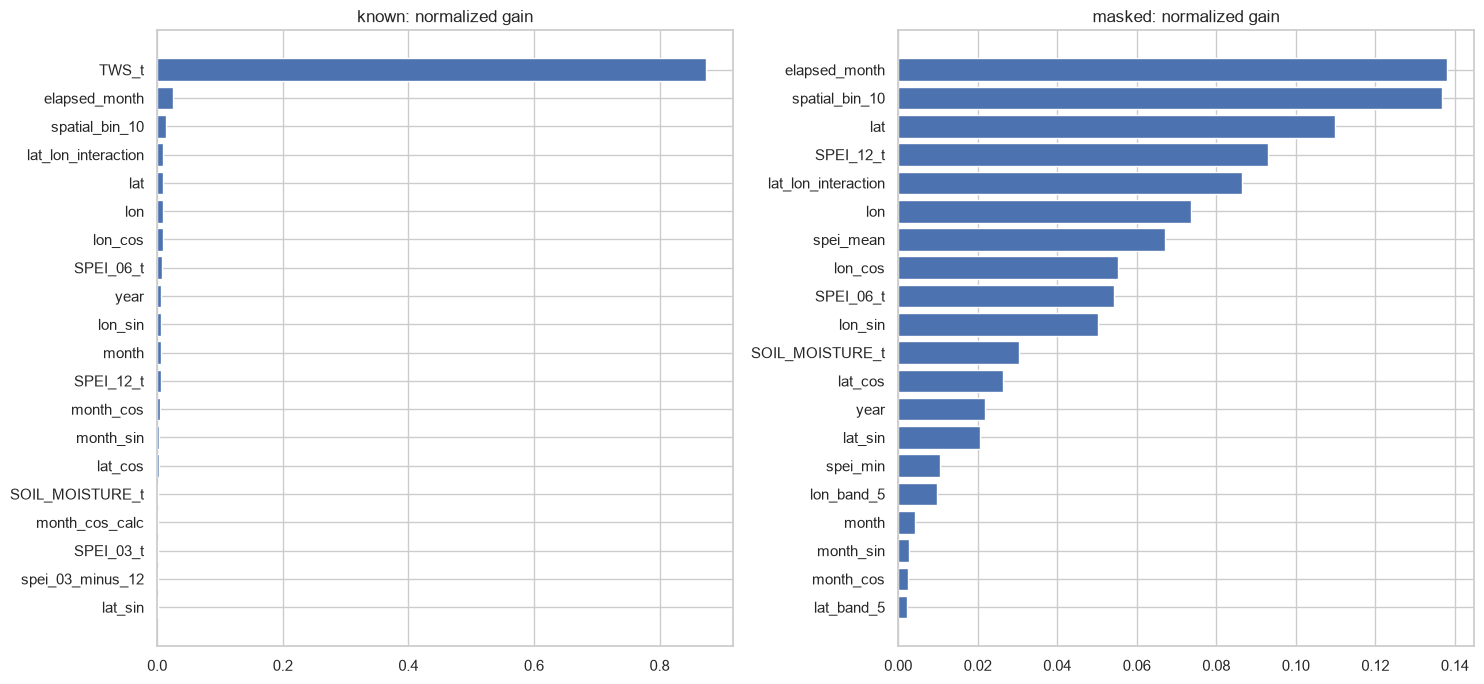

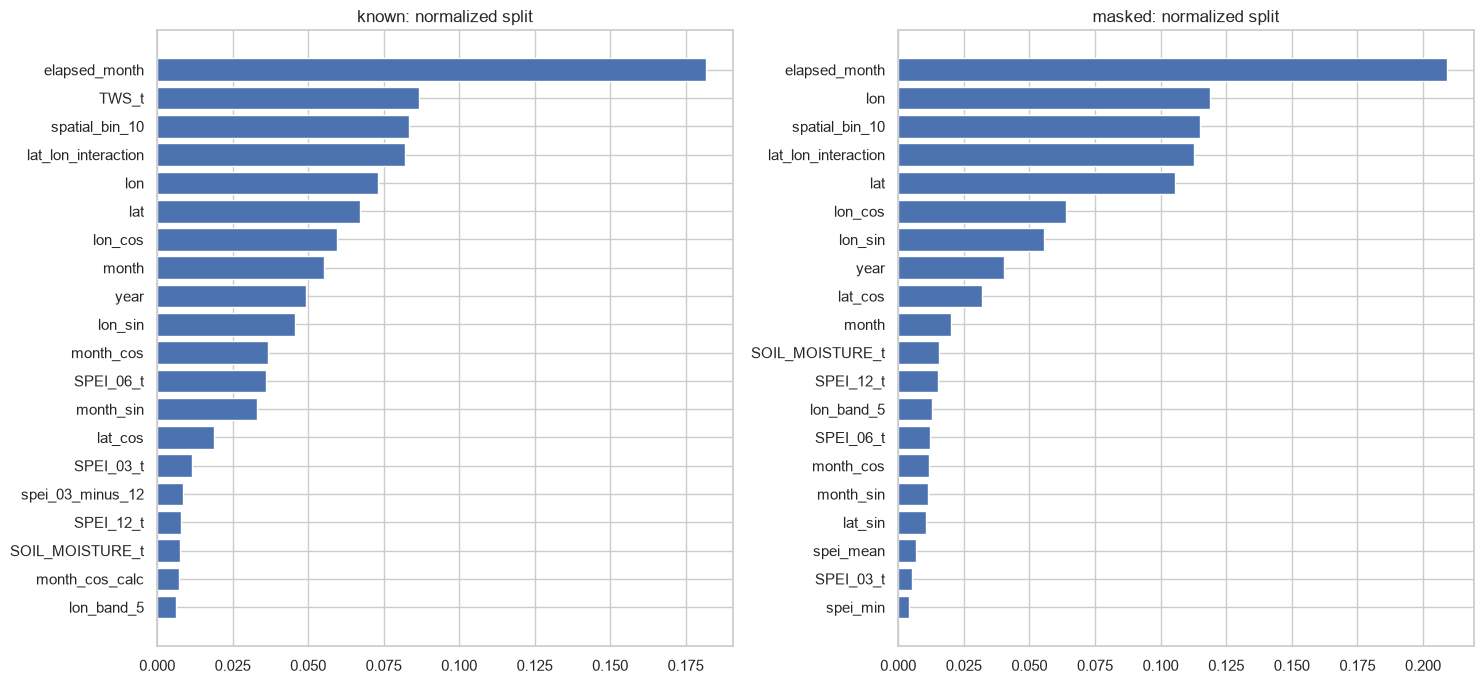

In [6]:
def plot_feature_importance(importance_df,importance_type="gain",top_n=20):
    d=(importance_df.groupby(["specialist","feature"])[importance_type].mean()
       .groupby(level=0,group_keys=False).apply(lambda x:x/x.sum()).reset_index())
    fig,axes=plt.subplots(1,2,figsize=(15,7))
    for ax,(name,g) in zip(axes,d.groupby("specialist")):
        top=g.nlargest(top_n,importance_type).sort_values(importance_type)
        ax.barh(top.feature,top[importance_type]); ax.set_title(f"{name}: normalized {importance_type}")
    plt.tight_layout(); plt.show()
    return d

gain_importance=plot_feature_importance(fold_importance,"gain")
split_importance=plot_feature_importance(fold_importance,"split")

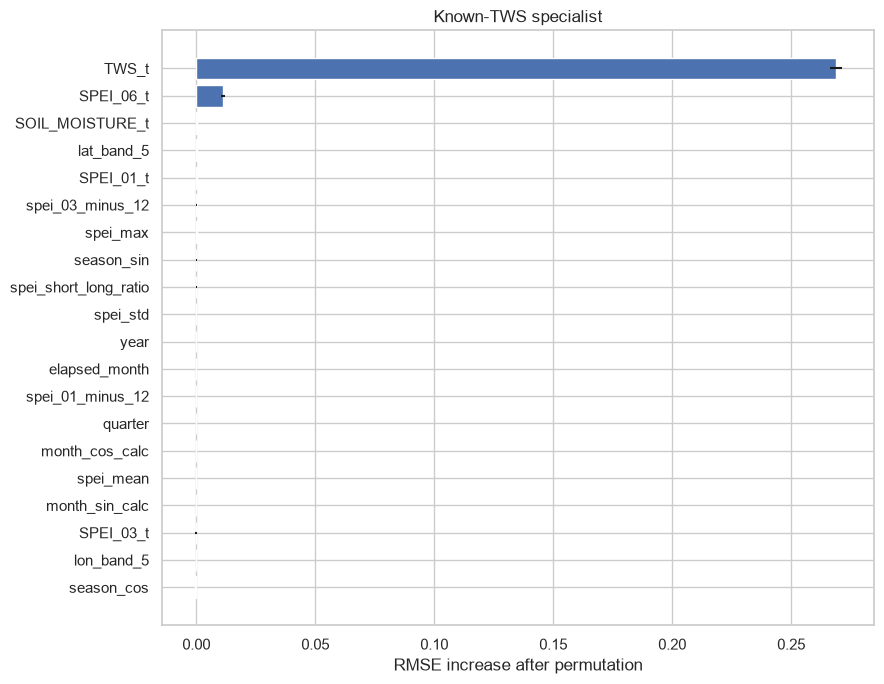

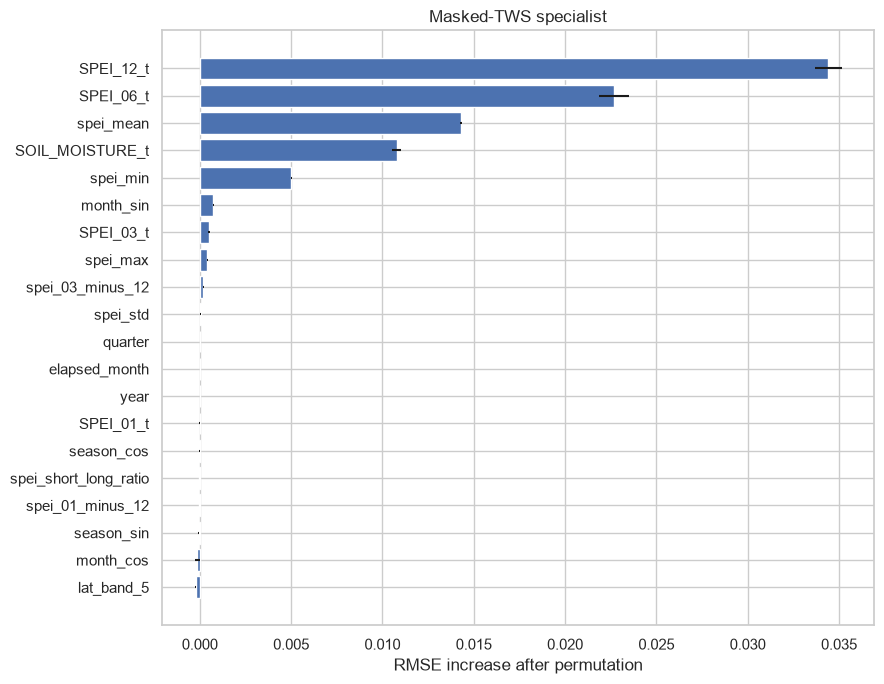

,feature,mean,std
2,TWS_t,0.268655,0.002546
5,SPEI_06_t,0.011178,0.001015
7,SOIL_MOISTURE_t,0.000403,0.000034
25,lat_band_5,0.000214,0.000070
3,SPEI_01_t,0.000166,0.000005
23,spei_03_minus_12,0.000117,0.000093
20,spei_max,0.000106,0.000004
16,season_sin,0.000047,0.000033
24,spei_short_long_ratio,0.000029,0.000025
21,spei_std,0.000027,0.000003


,feature,mean,std
5,SPEI_12_t,0.034412,0.000731
4,SPEI_06_t,0.022678,0.000810
17,spei_mean,0.014300,0.000044
6,SOIL_MOISTURE_t,0.010782,0.000251
18,spei_min,0.004998,0.000032
8,month_sin,0.000730,0.000020
3,SPEI_03_t,0.000504,0.000052
19,spei_max,0.000407,0.000037
22,spei_03_minus_12,0.000195,0.000011
20,spei_std,0.000060,0.000027


In [7]:
def plot_permutation_importance(model,X,y,top_n=20,title="Permutation importance"):
    n=min(12000,len(X)); idx=X.sample(n,random_state=SEED).index
    pi=permutation_importance(model,X.loc[idx],y.loc[idx],scoring="neg_root_mean_squared_error",
                              n_repeats=2,random_state=SEED,n_jobs=1)
    d=pd.DataFrame({"feature":X.columns,"mean":pi.importances_mean,"std":pi.importances_std})
    top=d.nlargest(top_n,"mean").sort_values("mean")
    plt.figure(figsize=(9,7)); plt.barh(top.feature,top["mean"],xerr=top["std"])
    plt.title(title); plt.xlabel("RMSE increase after permutation"); plt.tight_layout(); plt.show()
    return d.sort_values("mean",ascending=False)

tr_idx,va_idx=MODEL_SPLITS[-1]; tr=train_f.iloc[tr_idx]; va=train_f.iloc[va_idx]
last_dates=np.array(sorted(va.time.unique()))
last_known=va.time.isin({d for j,d in enumerate(last_dates) if j in KNOWN_DATE_POSITIONS})
perm_known=plot_permutation_importance(fold_models[-1][0],va.loc[last_known,FEATURES],
                                       va.loc[last_known,"target"],title="Known-TWS specialist")
perm_masked=plot_permutation_importance(fold_models[-1][1],va.loc[~last_known,NO_TWS_FEATURES],
                                        va.loc[~last_known,"target"],title="Masked-TWS specialist")
display(perm_known.head(20)); display(perm_masked.head(20))

### Feature anlamı ve leakage değerlendirmesi

- **TWS_t:** Bir-adım-ileri su depolama için fiziksel persistence bilgisidir; bu yüzden bilinen-TWS uzmanında baskın olması beklenir. Train target'ının sonraki gözlenen TWS ile çok yakın olması onu güçlü bir proxy yapar. Bu ilişki tek başına leakage kanıtı değildir; asıl risk testin çoğunda TWS'nin erişilememesidir.
- **SPEI_01/03/06/12:** Meteorolojik kuraklığın kısa ve uzun hafızasını temsil eder. Fark, ortalama, min/max ve oynaklık özellikleri akut kuraklık ile kalıcı kuraklığı ayırabilir. Birbirleriyle yüksek ilişkili olduklarından split importance katkıyı çok sayıda türeve dağıtabilir; permutation daha güvenilir tamamlayıcıdır.
- **SOIL_MOISTURE_t:** Yağışın ve evapotranspirasyonun kara yüzeyi üzerindeki yakın dönem etkisini taşır; TWS ile fiziksel olarak ilişkili fakat aynı büyüklük değildir.
- **month / döngüsel ay:** Mevsimsellik ve hemisfer farkları için yararlıdır. Ham month tek başına dairesel değildir; sin/cos eşleri bu sınırı giderir.
- **year / elapsed_month:** Uzun dönem trend ve sensör/iklim rejimi değişimini yakalayabilir. Ağaçlar geleceğe extrapolate edemediğinden yüksek önem, genellenebilir trendden çok dönem tanıma işareti de olabilir.
- **lat/lon ve spatial türevler:** İklim kuşağı, kara örtüsü ve hidrolojik rejim için düşük çözünürlüklü proxy'dir. Target encoding kullanılmadığı için doğrudan target leakage yoktur; aynı konumların geleceğini tahmin etme senaryosunda memorization riski yine izlenmelidir.

Gain, split ve permutation sıralamalarının uyuşması güçlü kanıt; ayrışması ise korelasyon ve alternatif split yollarının işaretidir.

## 4. Opsiyonel SHAP

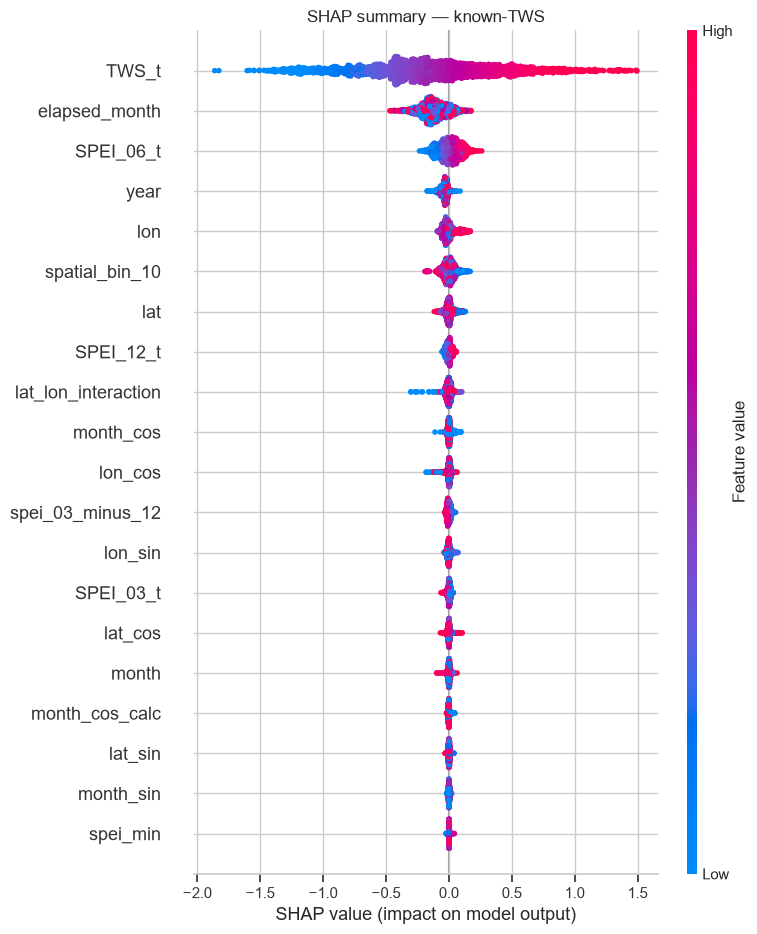

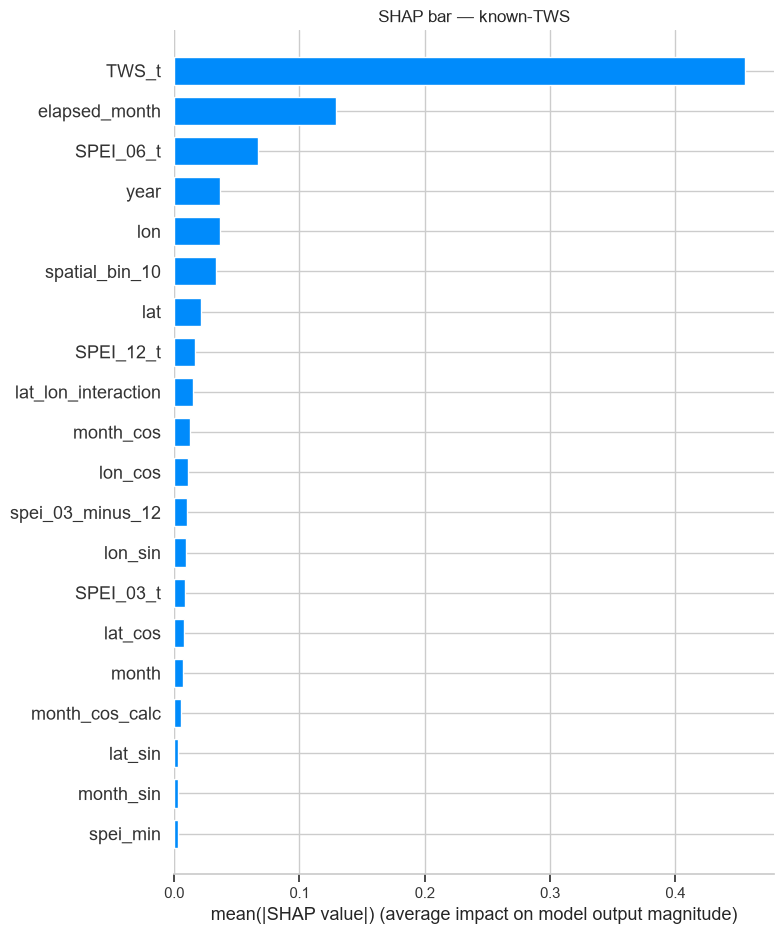

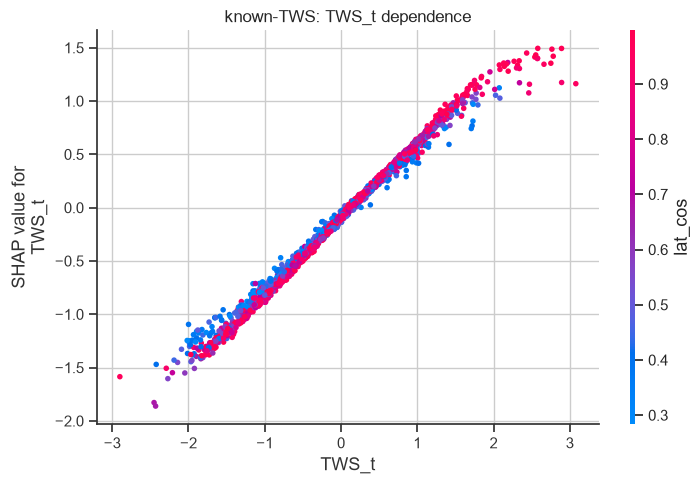

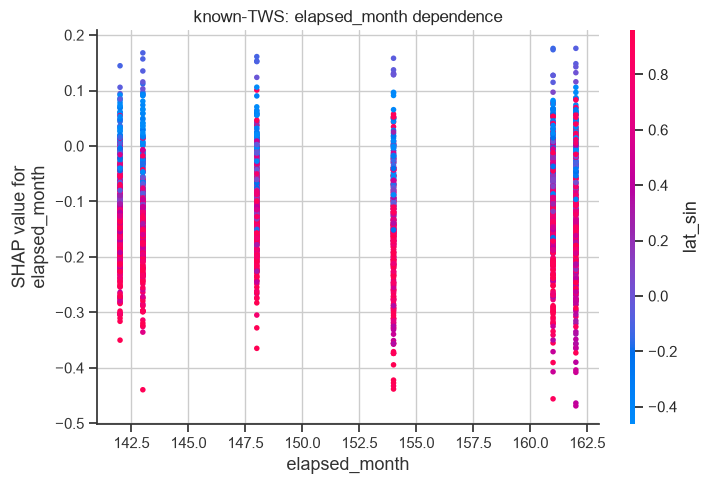

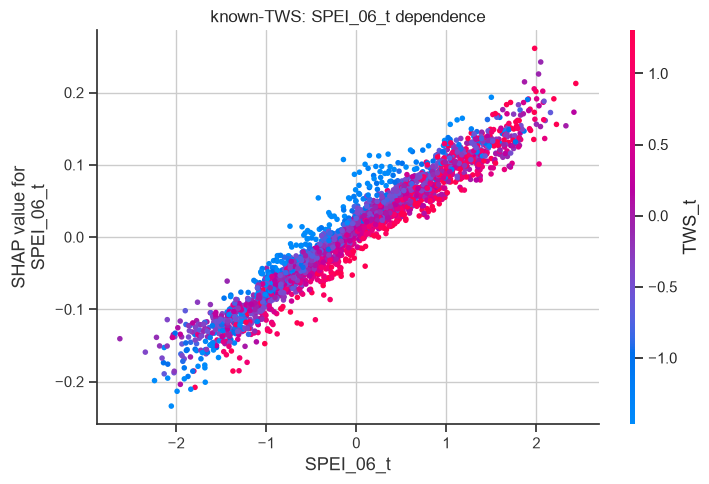

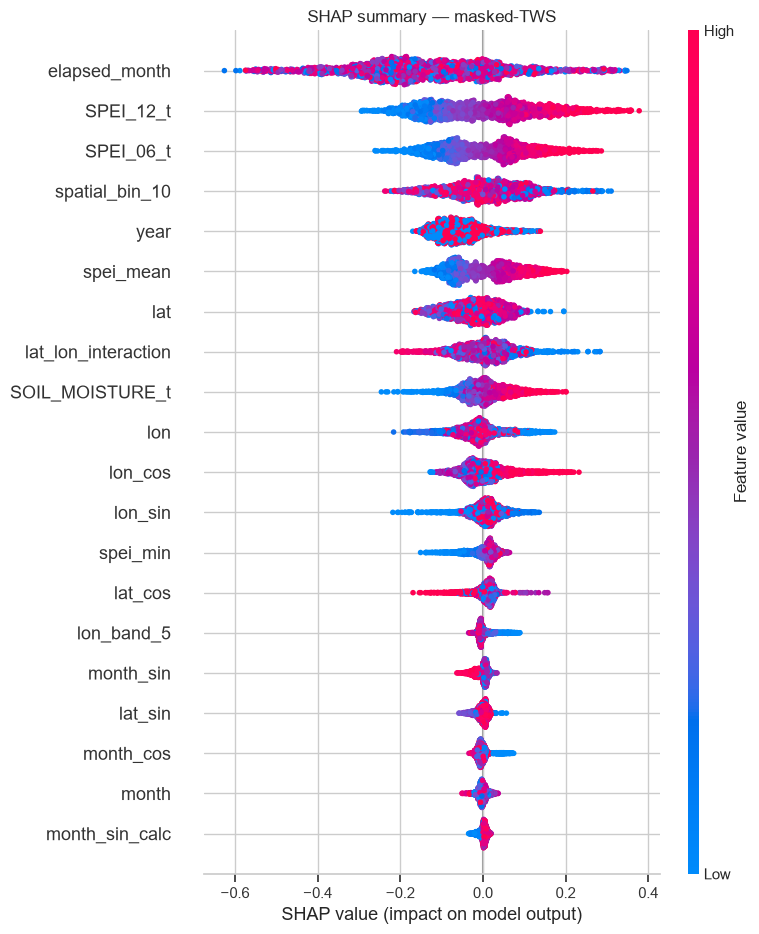

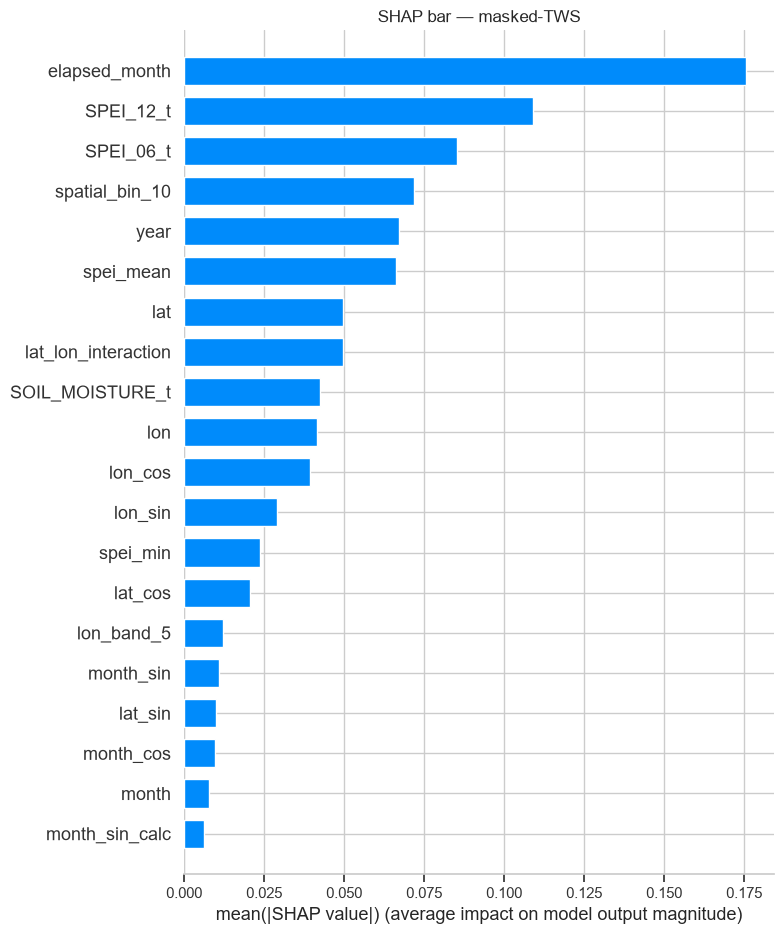

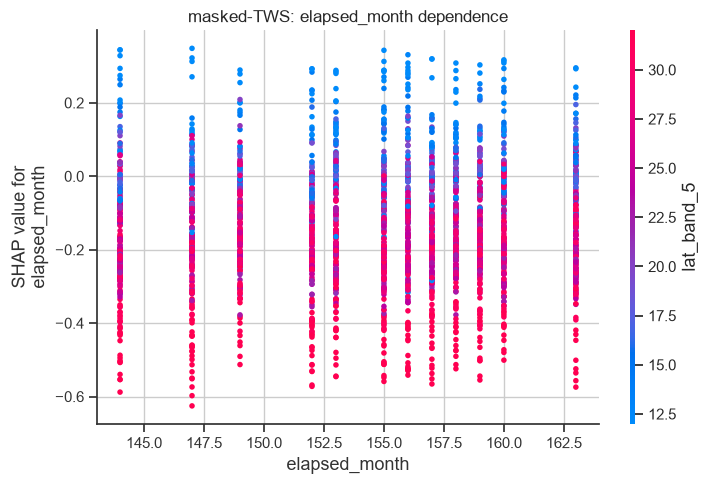

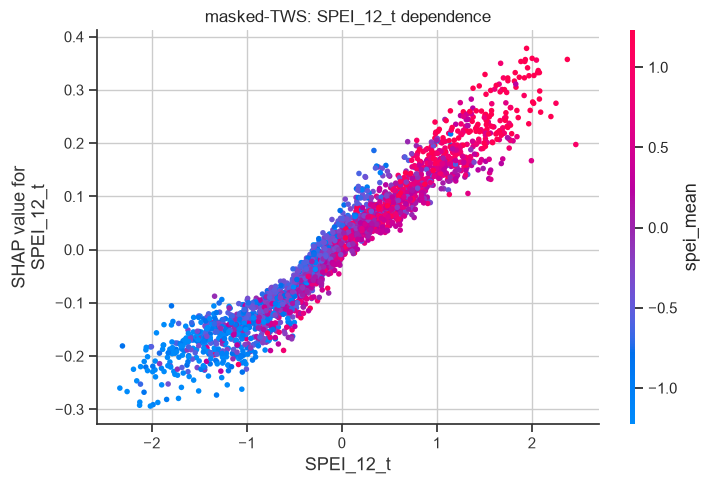

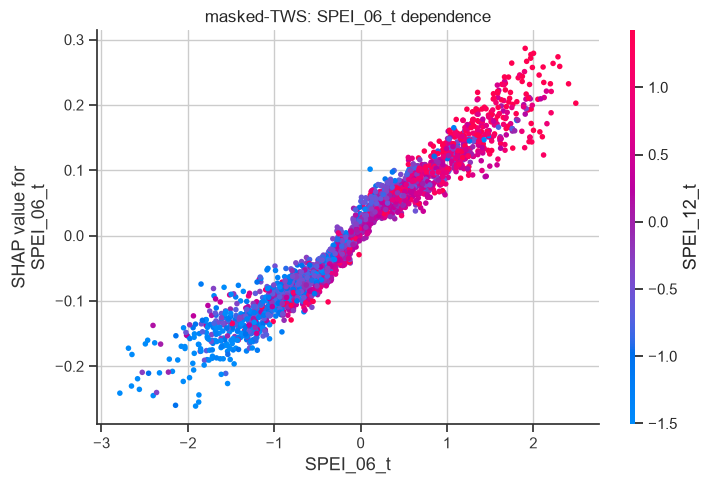

In [8]:
SHAP_AVAILABLE=importlib.util.find_spec("shap") is not None
def plot_shap_summary(model,X,label,max_rows=2500):
    if not SHAP_AVAILABLE:
        print("SHAP kurulu değil; hücre atlandı."); return None
    import shap
    xs=X.sample(min(max_rows,len(X)),random_state=SEED)
    explainer=shap.TreeExplainer(model)
    values=explainer.shap_values(xs)
    shap.summary_plot(values,xs,show=False,max_display=20)
    plt.title(f"SHAP summary — {label}"); plt.tight_layout(); plt.show()
    shap.summary_plot(values,xs,plot_type="bar",show=False,max_display=20)
    plt.title(f"SHAP bar — {label}"); plt.tight_layout(); plt.show()
    mean_abs=pd.Series(np.abs(values).mean(axis=0),index=xs.columns).sort_values(ascending=False)
    for f in mean_abs.head(3).index:
        shap.dependence_plot(f,values,xs,show=False)
        plt.title(f"{label}: {f} dependence"); plt.tight_layout(); plt.show()
    return mean_abs

shap_known=plot_shap_summary(fold_models[-1][0],va.loc[last_known,FEATURES],"known-TWS")
shap_masked=plot_shap_summary(fold_models[-1][1],va.loc[~last_known,NO_TWS_FEATURES],"masked-TWS")

## 5. Residual ve genel hata analizi

RMSE        0.713889
MAE         0.540541
MedianAE    0.419234
R2          0.288809
Name: OOF metrics, dtype: float64

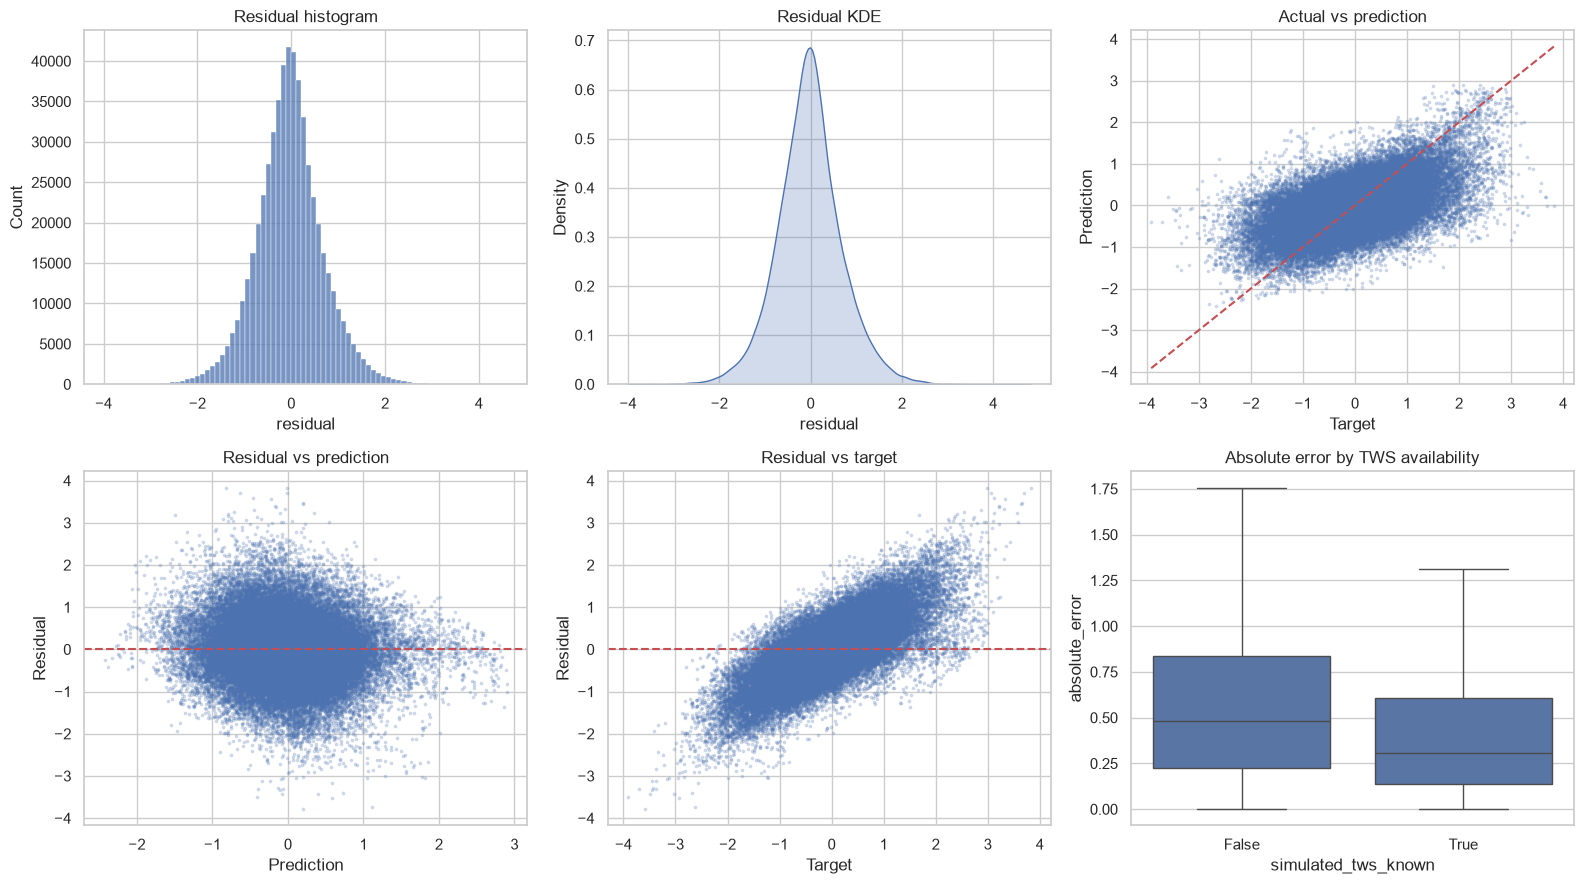

In [9]:
def plot_residuals(df):
    fig,axes=plt.subplots(2,3,figsize=(16,9))
    sns.histplot(df.residual,bins=80,ax=axes[0,0]); axes[0,0].set_title("Residual histogram")
    sns.kdeplot(data=df.sample(min(100000,len(df)),random_state=SEED),x="residual",fill=True,ax=axes[0,1])
    axes[0,1].set_title("Residual KDE")
    s=df.sample(min(60000,len(df)),random_state=SEED)
    axes[0,2].scatter(s.target,s.prediction,s=3,alpha=.2)
    lim=[min(s.target.min(),s.prediction.min()),max(s.target.max(),s.prediction.max())]
    axes[0,2].plot(lim,lim,"r--"); axes[0,2].set(title="Actual vs prediction",xlabel="Target",ylabel="Prediction")
    axes[1,0].scatter(s.prediction,s.residual,s=3,alpha=.2); axes[1,0].axhline(0,color="r",ls="--")
    axes[1,0].set(title="Residual vs prediction",xlabel="Prediction",ylabel="Residual")
    axes[1,1].scatter(s.target,s.residual,s=3,alpha=.2); axes[1,1].axhline(0,color="r",ls="--")
    axes[1,1].set(title="Residual vs target",xlabel="Target",ylabel="Residual")
    sns.boxplot(data=df,x="simulated_tws_known",y="absolute_error",showfliers=False,ax=axes[1,2])
    axes[1,2].set_title("Absolute error by TWS availability")
    plt.tight_layout(); plt.show()

display(pd.Series(regression_metrics(oof.target,oof.prediction),name="OOF metrics"))
plot_residuals(oof)

In [10]:
def analyze_worst_predictions(df,quantile=.95):
    threshold=df.absolute_error.quantile(quantile)
    cols=["sample_id","time","lat","lon",*FEATURES,"prediction","target","absolute_error","fold","simulated_tws_known"]
    worst=df.loc[df.absolute_error>=threshold,cols].sort_values("absolute_error",ascending=False)
    print(f"Worst {100*(1-quantile):.0f}% threshold:",threshold,"rows:",len(worst))
    return worst

worst_5=analyze_worst_predictions(oof)
display(worst_5.head(50))
display(worst_5[["target","prediction","absolute_error","TWS_t",*SPEI_COLS,"SOIL_MOISTURE_t"]].describe())

Worst 5% threshold: 1.4599890957287902 rows: 28100


,sample_id,time,lat,lon,lat,lon,TWS_t,SPEI_01_t,SPEI_03_t,SPEI_06_t,SPEI_12_t,SOIL_MOISTURE_t,month,month_sin,month_cos,year,quarter,elapsed_month,month_sin_calc,month_cos_calc,season_sin,season_cos,spei_mean,spei_min,spei_max,spei_std,spei_01_minus_12,spei_03_minus_12,spei_short_long_ratio,lat_band_5,lon_band_5,spatial_bin_10,lat_lon_interaction,lat_sin,lat_cos,lon_sin,lon_cos,prediction,target,absolute_error,fold,simulated_tws_known
457980,20150201_23.5_22.5,2015-02-01,23.5,22.5,23.5,22.5,-0.396195,1.289940,0.321235,-0.347329,-0.512147,-0.267623,2,0.866025,0.5,2015,1,157,0.866025,0.5,1.0,6.123234e-17,0.187925,-0.512147,1.289940,0.818292,1.802087,0.833382,2.107239,22.0,40.0,2240.0,0.52875,0.398749,0.917060,0.382683,0.923880,-0.545598,4.057275,4.602873,2,False
457979,20150201_23.5_21.5,2015-02-01,23.5,21.5,23.5,21.5,-0.321607,1.366869,0.358899,-0.127370,-0.145651,-0.282627,2,0.866025,0.5,2015,1,157,0.866025,0.5,1.0,6.123234e-17,0.363187,-0.145651,1.366869,0.708745,1.512520,0.504550,5.564267,22.0,40.0,2240.0,0.50525,0.398749,0.917060,0.366501,0.930418,-0.549421,4.024184,4.573605,2,False
457981,20150201_23.5_23.5,2015-02-01,23.5,23.5,23.5,23.5,-0.761081,1.303864,0.379064,-0.395108,-0.423236,-0.255215,2,0.866025,0.5,2015,1,157,0.866025,0.5,1.0,6.123234e-17,0.216146,-0.423236,1.303864,0.814885,1.727100,0.802301,2.491922,22.0,40.0,2240.0,0.55225,0.398749,0.917060,0.398749,0.917060,-0.544508,4.005284,4.549792,2,False
458113,20150201_24.5_22.5,2015-02-01,24.5,22.5,24.5,22.5,1.265269,1.058774,0.246127,-0.542434,-0.390475,-0.249112,2,0.866025,0.5,2015,1,157,0.866025,0.5,1.0,6.123234e-17,0.092998,-0.542434,1.058774,0.728856,1.449249,0.636602,2.158672,22.0,40.0,2240.0,0.55125,0.414693,0.909961,0.382683,0.923880,-0.473062,4.026746,4.499808,2,False
457853,20150201_22.5_23.5,2015-02-01,22.5,23.5,22.5,23.5,-2.028997,1.286626,0.231268,-0.181271,-0.331935,-0.262019,2,0.866025,0.5,2015,1,157,0.866025,0.5,1.0,6.123234e-17,0.251172,-0.331935,1.286626,0.730202,1.618562,0.563203,2.978748,22.0,40.0,2240.0,0.52875,0.382683,0.923880,0.398749,0.917060,-0.589963,3.887134,4.477097,2,False
458114,20150201_24.5_23.5,2015-02-01,24.5,23.5,24.5,23.5,1.271308,1.073049,0.427608,-0.323846,-0.372775,-0.266705,2,0.866025,0.5,2015,1,157,0.866025,0.5,1.0,6.123234e-17,0.201009,-0.372775,1.073049,0.687144,1.445823,0.800383,2.269683,22.0,40.0,2240.0,0.57575,0.414693,0.909961,0.398749,0.917060,-0.472868,3.996524,4.469392,2,False
458112,20150201_24.5_21.5,2015-02-01,24.5,21.5,24.5,21.5,0.905064,0.969231,0.180344,-0.564353,-0.301575,-0.264858,2,0.866025,0.5,2015,1,157,0.866025,0.5,1.0,6.123234e-17,0.070912,-0.564353,0.969231,0.673612,1.270805,0.481918,2.413575,22.0,40.0,2240.0,0.52675,0.414693,0.909961,0.366501,0.930418,-0.440680,3.954224,4.394904,2,False
457978,20150201_23.5_20.5,2015-02-01,23.5,20.5,23.5,20.5,-0.551507,1.253370,0.184875,-0.531416,-0.311871,-0.252597,2,0.866025,0.5,2015,1,157,0.866025,0.5,1.0,6.123234e-17,0.148739,-0.531416,1.253370,0.795045,1.565242,0.496746,3.043113,22.0,40.0,2240.0,0.48175,0.398749,0.917060,0.350207,0.936672,-0.534916,3.845732,4.380648,2,False
457852,20150201_22.5_20.5,2015-02-01,22.5,20.5,22.5,20.5,-1.045083,1.385692,0.311532,-0.204293,-0.246231,-0.248036,2,0.866025,0.5,2015,1,157,0.866025,0.5,1.0,6.123234e-17,0.311675,-0.246231,1.385692,0.759604,1.631923,0.557762,4.002219,22.0,40.0,2240.0,0.46125,0.382683,0.923880,0.350207,0.936672,-0.564968,3.802671,4.367639,2,False
458115,20150201_24.5_24.5,2015-02-01,24.5,24.5,24.5,24.5,0.839496,1.055118,0.298038,-0.306259,-0.413498,-0.298353,2,0.866025,0.5,2015,1,157,0.866025,0.5,1.0,6.123234e-17,0.158350,-0.413498,1.055118,0.674927,1.468616,0.711537,2.054765,22.0,40.0,2240.0,0.60025,0.414693,0.909961,0.414693,0.909961,-0.485802,3.799529,4.285331,2,False


,target,prediction,absolute_error,TWS_t,SPEI_01_t,SPEI_03_t,SPEI_06_t,SPEI_12_t,SOIL_MOISTURE_t
count,28100.000000,28100.000000,28100.000000,28100.000000,28100.000000,28100.000000,28100.000000,28100.000000,28100.000000
mean,-0.012304,-0.042870,1.844697,-0.002319,0.045652,-0.042736,-0.067392,-0.091549,-0.009391
std,1.752769,0.573682,0.368068,1.237261,1.007725,0.980088,0.967634,0.970112,0.828471
min,-3.968328,-2.179824,1.459997,-3.968328,-3.179114,-3.554383,-3.518493,-3.449462,-4.055198
25%,-1.652979,-0.410797,1.577931,-0.948060,-0.711267,-0.757704,-0.778598,-0.812482,-0.447890
50%,0.266789,-0.041800,1.735562,-0.013707,0.032059,-0.059841,-0.096100,-0.098891,-0.010046
75%,1.607218,0.312003,2.001900,0.883126,0.812001,0.679647,0.653938,0.598600,0.495137
max,4.057275,2.628963,4.602873,3.777452,2.853918,3.127879,2.937386,3.028550,5.377813


## 6. Temporal ve spatial error

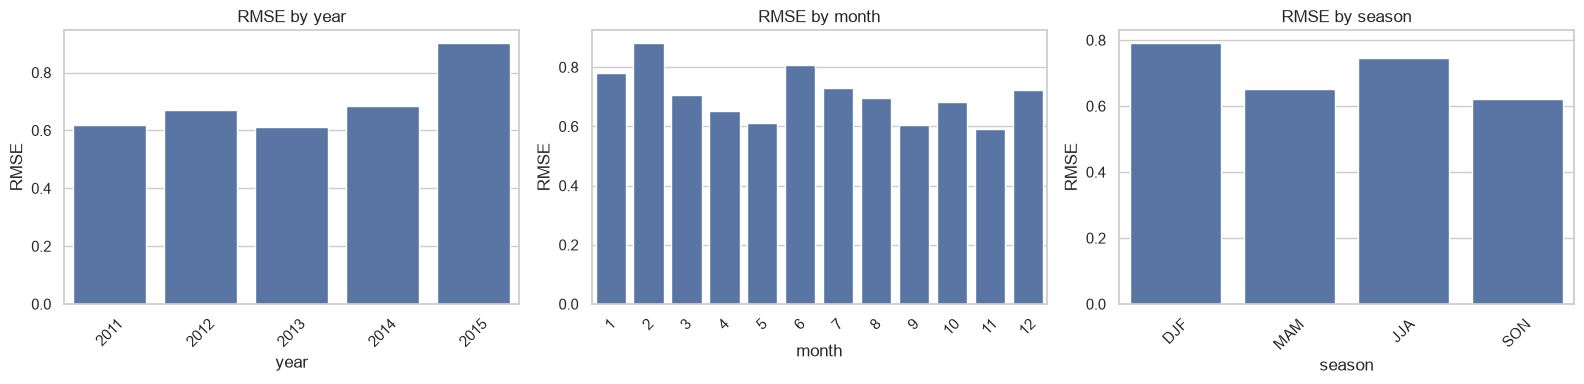

year


,year,n,RMSE,MAE
4,2015,124929.0,0.900269,0.698316
3,2014,124882.0,0.683920,0.519197
1,2012,124892.0,0.670555,0.521688
0,2011,77999.0,0.617713,0.460199
2,2013,109296.0,0.611207,0.463464


month


,month,n,RMSE,MAE
1,2,47001.0,0.880015,0.660420
5,6,46736.0,0.808292,0.599331
0,1,62597.0,0.781272,0.609721
6,7,46758.0,0.729412,0.565852
11,12,62534.0,0.723563,0.557019
2,3,31328.0,0.706169,0.557191
7,8,46604.0,0.695215,0.523414
9,10,31228.0,0.681332,0.531816
3,4,46918.0,0.653648,0.501774
4,5,46744.0,0.611722,0.452720


season


,season,n,RMSE,MAE
0,DJF,172132.0,0.789701,0.604418
2,JJA,140098.0,0.745854,0.562903
1,MAM,124990.0,0.652163,0.497319
3,SON,124778.0,0.620047,0.470608


In [11]:
def grouped_errors(df,group):
    return (df.groupby(group,observed=True)
            .apply(lambda x:pd.Series({"n":len(x),"RMSE":root_mean_squared_error(x.target,x.prediction),
                                       "MAE":mean_absolute_error(x.target,x.prediction)}))
            .reset_index())

def plot_temporal_errors(df):
    d=df.copy(); d["year"]=d.time.dt.year; d["month"]=d.time.dt.month
    d["season"]=pd.Categorical(d.month.map({12:"DJF",1:"DJF",2:"DJF",3:"MAM",4:"MAM",5:"MAM",
        6:"JJA",7:"JJA",8:"JJA",9:"SON",10:"SON",11:"SON"}),["DJF","MAM","JJA","SON"],ordered=True)
    tables={x:grouped_errors(d,x) for x in ["year","month","season"]}
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    for ax,(name,t) in zip(axes,tables.items()):
        sns.barplot(data=t,x=name,y="RMSE",ax=ax); ax.tick_params(axis="x",rotation=45); ax.set_title(f"RMSE by {name}")
    plt.tight_layout(); plt.show()
    return tables

temporal_tables=plot_temporal_errors(oof)
for name,t in temporal_tables.items(): print(name); display(t.sort_values("RMSE",ascending=False))

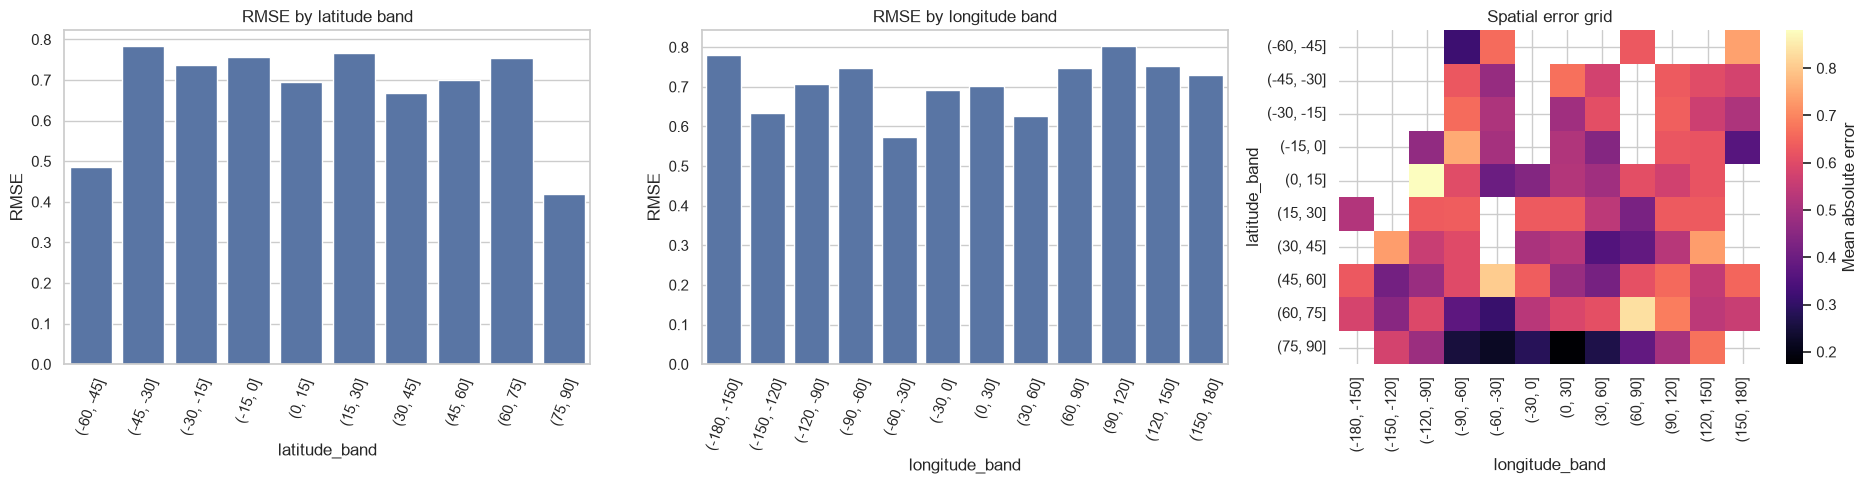

,latitude_band,n,RMSE,MAE
1,"(-45, -30]",17469.0,0.782946,0.603785
5,"(15, 30]",65324.0,0.765517,0.580977
3,"(-15, 0]",44829.0,0.757329,0.571892
8,"(60, 75]",115136.0,0.754717,0.580836
2,"(-30, -15]",45339.0,0.737332,0.559194


,longitude_band,n,RMSE,MAE
9,"(90, 120]",71399.0,0.801965,0.619512
0,"(-180, -150]",7596.0,0.779501,0.587257
10,"(120, 150]",56689.0,0.751943,0.579321
8,"(60, 90]",57812.0,0.748197,0.563122
3,"(-90, -60]",69532.0,0.746662,0.565077


In [12]:
def plot_spatial_errors(df):
    d=df.copy()
    d["latitude_band"]=pd.cut(d.lat,np.arange(-60,91,15))
    d["longitude_band"]=pd.cut(d.lon,np.arange(-180,181,30))
    lat=grouped_errors(d,"latitude_band"); lon=grouped_errors(d,"longitude_band")
    grid=(d.groupby(["latitude_band","longitude_band"],observed=True).absolute_error.mean().unstack())
    fig,axes=plt.subplots(1,3,figsize=(19,5))
    sns.barplot(data=lat,x="latitude_band",y="RMSE",ax=axes[0]); axes[0].tick_params(axis="x",rotation=70)
    sns.barplot(data=lon,x="longitude_band",y="RMSE",ax=axes[1]); axes[1].tick_params(axis="x",rotation=70)
    sns.heatmap(grid,ax=axes[2],cmap="magma",cbar_kws={"label":"Mean absolute error"})
    axes[0].set_title("RMSE by latitude band"); axes[1].set_title("RMSE by longitude band")
    axes[2].set_title("Spatial error grid"); plt.tight_layout(); plt.show()
    return lat,lon,grid

lat_errors,lon_errors,spatial_grid=plot_spatial_errors(oof)
display(lat_errors.sort_values("RMSE",ascending=False).head())
display(lon_errors.sort_values("RMSE",ascending=False).head())

## 7. Prediction dağılımları

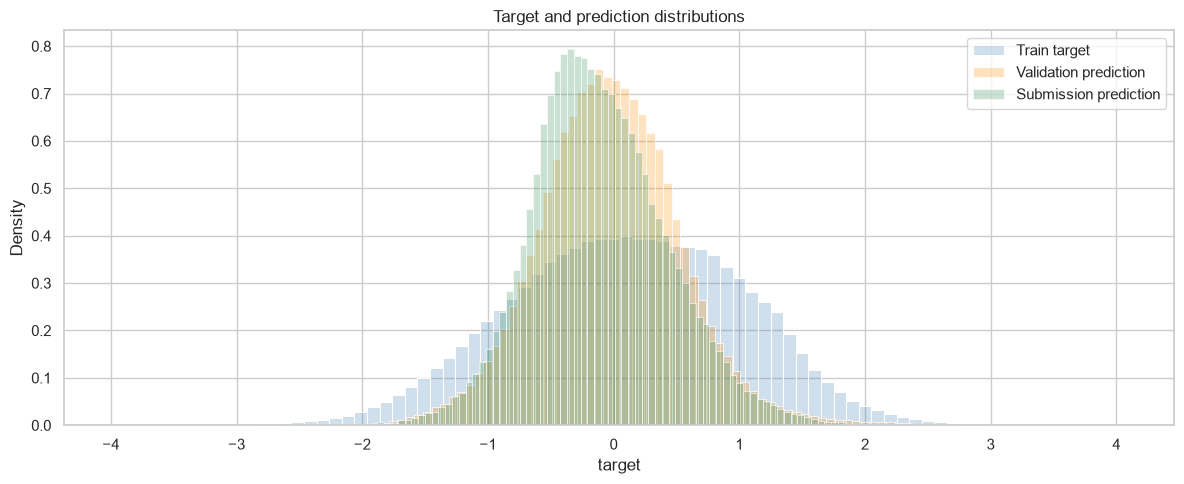

,train_target,validation_prediction,submission_prediction
count,2.154021e+06,561998.000000,280961.000000
mean,1.125038e-01,-0.025614,-0.112960
std,9.119618e-01,0.572576,0.539841
min,-3.968328e+00,-2.471454,-2.255716
25%,-5.294420e-01,-0.394034,-0.475090
50%,1.273017e-01,-0.037904,-0.151043
75%,7.807068e-01,0.327155,0.224641
max,4.057275e+00,2.988972,2.054586


In [13]:
plt.figure(figsize=(12,5))
sns.histplot(train.target,stat="density",bins=80,color="steelblue",alpha=.25,label="Train target")
sns.histplot(oof.prediction,stat="density",bins=80,color="darkorange",alpha=.25,label="Validation prediction")
sns.histplot(submission.Target,stat="density",bins=80,color="seagreen",alpha=.25,label="Submission prediction")
plt.legend(); plt.title("Target and prediction distributions"); plt.tight_layout(); plt.show()
distribution_summary=pd.DataFrame({
    "train_target":train.target.describe(),
    "validation_prediction":oof.prediction.describe(),
    "submission_prediction":submission.Target.describe()
})
display(distribution_summary)

## 8. Fold stability

,fold,RMSE,MAE,MedianAE,R2,known_RMSE,masked_RMSE
0,1,0.646900,0.495291,0.390439,0.427100,0.509031,0.705685
1,2,0.775083,0.585770,0.452407,0.145108,0.693215,0.812902


fold                                   1         2  abs_change
specialist feature                                            
masked     lat                  0.131612  0.090450    0.041161
           elapsed_month        0.124105  0.150179    0.026074
           SPEI_12_t            0.083082  0.101757    0.018676
           lon_sin              0.053654  0.047231    0.006423
           spatial_bin_10       0.134071  0.139010    0.004939
           lat_sin              0.022849  0.018676    0.004173
           year                 0.019969  0.023656    0.003687
           SPEI_06_t            0.055855  0.052774    0.003081
           spei_min             0.008974  0.011917    0.002943
           SOIL_MOISTURE_t      0.028767  0.031659    0.002892
           lat_cos              0.027689  0.025299    0.002390
           lat_lon_interaction  0.087421  0.085420    0.002002
           spei_max             0.000336  0.002093    0.001757
           spei_mean            0.066230  0.067927    0.001697
           month                0.004904  0.003593    0.001311
known      elapsed_month        0.023982  0.025209    0.001227
           SPEI_12_t            0.005051  0.006034    0.000982
           lat                  0.009413  0.008525    0.000888
masked     lat_band_5           0.002622  0.001758    0.000864
known      month_sin            0.004002  0.003184    0.000817
           lon                  0.009323  0.008552    0.000771
           lat_cos              0.002409  0.003134    0.000726
           lat_lon_interaction  0.010263  0.009638    0.000624
           month_cos            0.004796  0.004197    0.000599
masked     month_cos            0.002723  0.002157    0.000566

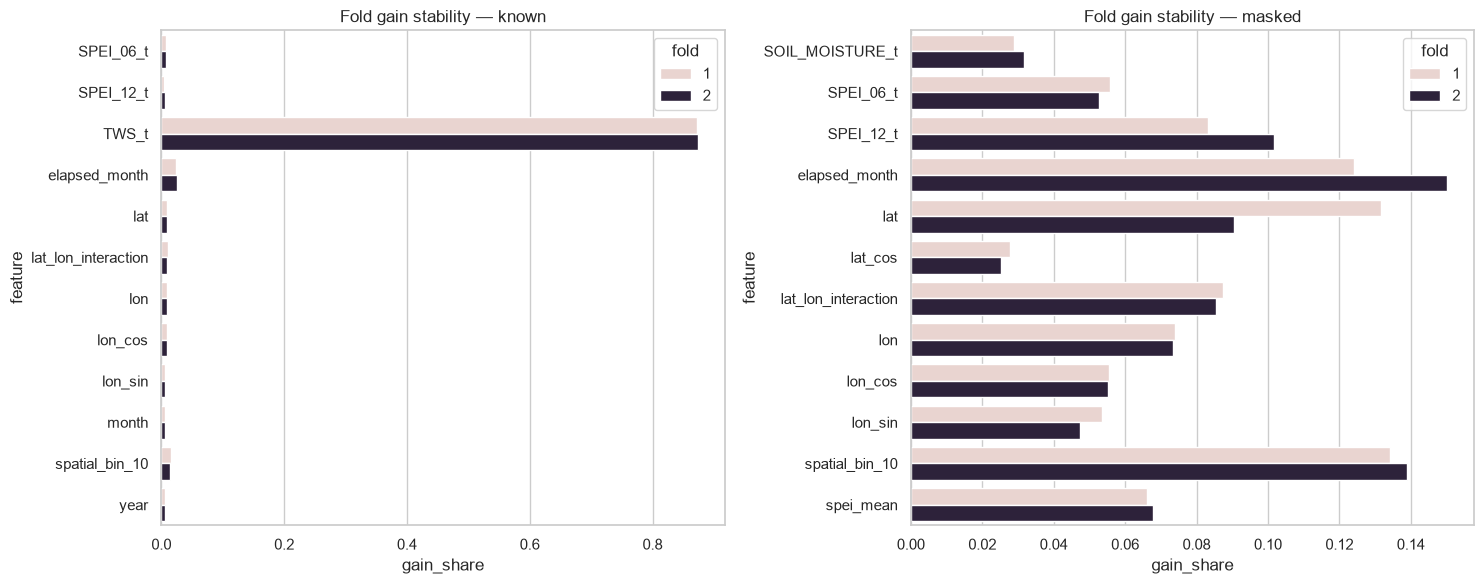

In [14]:
stability=(fold_importance.groupby(["fold","specialist","feature"]).gain.sum()
           .groupby(["fold","specialist"],group_keys=False).apply(lambda x:x/x.sum()).rename("gain_share").reset_index())
rank_pivot=stability.pivot_table(index=["specialist","feature"],columns="fold",values="gain_share",fill_value=0)
rank_pivot["abs_change"]=abs(rank_pivot.iloc[:,0]-rank_pivot.iloc[:,1])
display(fold_metrics)
display(rank_pivot.sort_values("abs_change",ascending=False).head(25))

fig,axes=plt.subplots(1,2,figsize=(15,6))
for ax,(specialist,g) in zip(axes,stability.groupby("specialist")):
    top=g.groupby("feature").gain_share.mean().nlargest(12).index
    sns.barplot(data=g[g.feature.isin(top)],y="feature",x="gain_share",hue="fold",ax=ax)
    ax.set_title(f"Fold gain stability — {specialist}")
plt.tight_layout(); plt.show()

## 9. Empirik uncertainty: fold-model disagreement

In [15]:
def add_fold_disagreement(df,models):
    out=df.copy(); known=out.simulated_tws_known.to_numpy()
    matrix=[]
    for mk,mm in models:
        p=np.empty(len(out))
        p[known]=mk.predict(out.loc[known,FEATURES])
        p[~known]=mm.predict(out.loc[~known,NO_TWS_FEATURES])
        matrix.append(p)
    out["fold_prediction_std"]=np.std(np.vstack(matrix),axis=0)
    return out

uncertainty=add_fold_disagreement(oof,fold_models)
print("Correlation disagreement vs absolute error:",
      uncertainty.fold_prediction_std.corr(uncertainty.absolute_error))
display(uncertainty.nsmallest(20,"fold_prediction_std")[["sample_id","time","lat","lon","prediction","target","absolute_error","fold_prediction_std"]])
display(uncertainty.nlargest(20,"fold_prediction_std")[["sample_id","time","lat","lon","prediction","target","absolute_error","fold_prediction_std",*SPEI_COLS,"SOIL_MOISTURE_t"]])
uncertainty["uncertainty_decile"]=pd.qcut(uncertainty.fold_prediction_std,10,duplicates="drop")
display(grouped_errors(uncertainty,"uncertainty_decile"))

Correlation disagreement vs absolute error: 0.22923857718339344


,sample_id,time,lat,lon,prediction,target,absolute_error,fold_prediction_std
97412,20120201_8.5_5.5,2012-02-01,8.5,5.5,-0.297472,-0.073555,0.223917,1.747927e-07
166051,20120801_51.5_35.5,2012-08-01,51.5,35.5,-0.632837,-0.334913,0.297924,5.933256e-07
336618,20140401_45.5_93.5,2014-04-01,45.5,93.5,-0.395372,0.257347,0.652719,1.350718e-06
299550,20131201_-0.5_-78.5,2013-12-01,-0.5,-78.5,-0.344568,-0.731345,0.386777,1.454439e-06
517969,20150601_-4.5_17.5,2015-06-01,-4.5,17.5,-0.503555,-1.487900,0.984345,2.180675e-06
180218,20120901_44.5_101.5,2012-09-01,44.5,101.5,0.101019,-0.079790,0.180809,2.662725e-06
189277,20121201_-12.5_-54.5,2012-12-01,-12.5,-54.5,0.462974,0.263954,0.199020,3.394653e-06
14703,20110801_73.5_-93.5,2011-08-01,73.5,-93.5,-0.149310,-0.179842,0.030532,3.832837e-06
511434,20150501_60.5_-129.5,2015-05-01,60.5,-129.5,0.273172,-0.078724,0.351895,4.133936e-06
12976,20110801_65.5_-118.5,2011-08-01,65.5,-118.5,-0.455426,0.779972,1.235399,4.845952e-06


,sample_id,time,lat,lon,prediction,target,absolute_error,fold_prediction_std,SPEI_01_t,SPEI_03_t,SPEI_06_t,SPEI_12_t,SOIL_MOISTURE_t
201872,20121201_71.5_99.5,2012-12-01,71.5,99.5,0.231175,-1.027797,1.258972,0.807817,-0.847848,-1.740824,-1.690099,-1.080912,-0.810131
201867,20121201_71.5_94.5,2012-12-01,71.5,94.5,0.250668,-1.115884,1.366552,0.806193,-1.430383,-1.909907,-1.622343,-0.822239,-0.594150
202008,20121201_72.5_98.5,2012-12-01,72.5,98.5,0.238476,-0.931098,1.169574,0.804521,-1.371246,-2.025289,-1.547800,-0.996939,-0.521978
279910,20130701_71.5_93.5,2013-07-01,71.5,93.5,0.236808,-1.545779,1.782587,0.803551,-2.046866,-3.094490,-2.097437,-1.722969,-0.612760
342604,20140401_72.5_105.5,2014-04-01,72.5,105.5,-1.492074,-0.220132,1.271942,0.803407,-1.568712,-0.825664,-1.067066,-2.125967,-2.408801
217653,20130101_72.5_99.5,2013-01-01,72.5,99.5,0.103956,-1.054030,1.157986,0.803331,-0.770091,-2.375614,-1.246153,-1.048586,-0.632006
202009,20121201_72.5_99.5,2012-12-01,72.5,99.5,0.233478,-0.949736,1.183214,0.801575,-1.191754,-1.848396,-1.523402,-1.052539,-0.624025
201868,20121201_71.5_95.5,2012-12-01,71.5,95.5,0.234811,-1.081727,1.316538,0.800992,-1.363181,-1.953885,-1.601511,-0.795649,-0.619761
201864,20121201_71.5_91.5,2012-12-01,71.5,91.5,0.298300,-1.248372,1.546672,0.800844,-1.731830,-1.932726,-1.064858,-0.659061,-0.298009
201866,20121201_71.5_93.5,2012-12-01,71.5,93.5,0.243125,-1.156046,1.399172,0.800815,-1.508268,-1.882915,-1.528498,-0.825213,-0.587419


,uncertainty_decile,n,RMSE,MAE
0,"(-0.000999825, 0.0188]",56200.0,0.586725,0.421970
1,"(0.0188, 0.0387]",56200.0,0.596692,0.432637
2,"(0.0387, 0.0605]",56200.0,0.614974,0.453180
3,"(0.0605, 0.0845]",56199.0,0.644386,0.481047
4,"(0.0845, 0.111]",56200.0,0.661344,0.497725
5,"(0.111, 0.14]",56200.0,0.691188,0.528569
6,"(0.14, 0.174]",56199.0,0.723760,0.557623
7,"(0.174, 0.221]",56200.0,0.775605,0.611373
8,"(0.221, 0.297]",56200.0,0.831926,0.665586
9,"(0.297, 0.808]",56200.0,0.932763,0.755696


## 10. Veri destekli final rapor

In [16]:
def generate_final_report():
    gain_top=(gain_importance.sort_values("gain",ascending=False).groupby("specialist").head(8)
              .groupby("specialist").feature.apply(lambda x:", ".join(x)).to_dict())
    worst_year=temporal_tables["year"].nlargest(1,"RMSE").iloc[0]
    worst_month=temporal_tables["month"].nlargest(1,"RMSE").iloc[0]
    worst_lat=lat_errors.nlargest(1,"RMSE").iloc[0]
    fold_mean=fold_metrics.RMSE.mean(); fold_std=fold_metrics.RMSE.std()
    uncertainty_corr=uncertainty.fold_prediction_std.corr(uncertainty.absolute_error)
    report=f'''
### Sonuç

- **Modelin güvendiği özellikler:** Known-TWS uzmanının üst gain özellikleri: `{gain_top.get('known','')}`. Masked-TWS uzmanının üst özellikleri: `{gain_top.get('masked','')}`.
- **TWS baskınlığı:** TWS_t bir-adım-ileri hedef için fiziksel persistence proxy'sidir. Yalnız mevcut olduğu uzman tarafından kullanılır; maskeli test satırlarına taşınmaz. Bu nedenle baskınlık beklenir, fakat tek başına leakage kanıtı değildir.
- **SPEI katkısı:** Gain/split/permutation ve SHAP tablolarında üst sıralarda kalan SPEI değişkenleri ek katkı kanıtıdır. Korelasyon nedeniyle tek tek önemleri bölünebilir; aile olarak değerlendirilmelidir.
- **Zor dönem:** En yüksek yıllık RMSE `{int(worst_year['year'])}` yılında `{worst_year.RMSE:.4f}`; en yüksek aylık RMSE ay `{int(worst_month['month'])}` için `{worst_month.RMSE:.4f}`.
- **Zor spatial kuşak:** En yüksek latitude-band RMSE `{worst_lat.latitude_band}` kuşağında `{worst_lat.RMSE:.4f}`.
- **Validation güvenilirliği:** Tarihler bütün halde geçmişten geleceğe ayrıldı; aynı konumların geleceği ve testin known/masked TWS deseni taklit edildi. İki fold RMSE ortalaması `{fold_mean:.4f}`, std `{fold_std:.4f}`.
- **Güçlü yönler:** Deployment koşuluna göre iki uzman, leakage-safe statik özellikler, aynı preprocessing ve birden fazla açıklama yöntemi.
- **Zayıf yönler:** Yalnız iki geç temporal fold; uzun/düzensiz test ufukları; spatial proxy'lerde memorization; ağaç modellerinin geleceğe trend extrapolasyonu sınırlı.
- **Overfitting:** Fold farkı ve gain-stability tablosu temporal hassasiyet gösterir. Train metriği hesaplanmadan kesin overfitting denemez; random validation ile temporal validation farkı iyimser IID değerlendirmenin riskini gösterir.
- **Belirsizlik:** Fold-model disagreement ile absolute error korelasyonu `{uncertainty_corr:.3f}`. Bu olasılıksal calibration değildir; göreli risk sinyalidir.
- **Sonraki adım:** Resmi horizon/target üretim kuralı netleştirilerek horizon-aware backtest, daha fazla rolling-origin fold ve calibrated conformal interval değerlendirmesi yapılmalıdır.
'''
    display(Markdown(report))
    return report

final_report=generate_final_report()


### Sonuç

- **Modelin güvendiği özellikler:** Known-TWS uzmanının üst gain özellikleri: `TWS_t, elapsed_month, spatial_bin_10, lat_lon_interaction, lat, lon, lon_cos, SPEI_06_t`. Masked-TWS uzmanının üst özellikleri: `elapsed_month, spatial_bin_10, lat, SPEI_12_t, lat_lon_interaction, lon, spei_mean, lon_cos`.
- **TWS baskınlığı:** TWS_t bir-adım-ileri hedef için fiziksel persistence proxy'sidir. Yalnız mevcut olduğu uzman tarafından kullanılır; maskeli test satırlarına taşınmaz. Bu nedenle baskınlık beklenir, fakat tek başına leakage kanıtı değildir.
- **SPEI katkısı:** Gain/split/permutation ve SHAP tablolarında üst sıralarda kalan SPEI değişkenleri ek katkı kanıtıdır. Korelasyon nedeniyle tek tek önemleri bölünebilir; aile olarak değerlendirilmelidir.
- **Zor dönem:** En yüksek yıllık RMSE `2015` yılında `0.9003`; en yüksek aylık RMSE ay `2` için `0.8800`.
- **Zor spatial kuşak:** En yüksek latitude-band RMSE `(-45, -30]` kuşağında `0.7829`.
- **Validation güvenilirliği:** Tarihler bütün halde geçmişten geleceğe ayrıldı; aynı konumların geleceği ve testin known/masked TWS deseni taklit edildi. İki fold RMSE ortalaması `0.7110`, std `0.0906`.
- **Güçlü yönler:** Deployment koşuluna göre iki uzman, leakage-safe statik özellikler, aynı preprocessing ve birden fazla açıklama yöntemi.
- **Zayıf yönler:** Yalnız iki geç temporal fold; uzun/düzensiz test ufukları; spatial proxy'lerde memorization; ağaç modellerinin geleceğe trend extrapolasyonu sınırlı.
- **Overfitting:** Fold farkı ve gain-stability tablosu temporal hassasiyet gösterir. Train metriği hesaplanmadan kesin overfitting denemez; random validation ile temporal validation farkı iyimser IID değerlendirmenin riskini gösterir.
- **Belirsizlik:** Fold-model disagreement ile absolute error korelasyonu `0.229`. Bu olasılıksal calibration değildir; göreli risk sinyalidir.
- **Sonraki adım:** Resmi horizon/target üretim kuralı netleştirilerek horizon-aware backtest, daha fazla rolling-origin fold ve calibrated conformal interval değerlendirmesi yapılmalıdır.


## Değişiklik özeti

- `09` ile aynı LightGBM, feature engineering ve iki uzmanlı temporal validation yeniden kuruldu.
- Gain, split, permutation ve opsiyonel SHAP açıklamaları eklendi.
- Residual, en kötü %5, temporal, spatial, dağılım, fold stability ve empirik uncertainty analizleri üretildi.
- Tüm sonuçlar çalıştırılmış hücre çıktılarından gelir; leaderboard target'ı veya uydurma metrik kullanılmadı.